# Задание 4.4
## Монета до двух одинаковых сторон подряд (симметричная)

### Условие:
«Симметричную» монету бросают, пока она не выпадет дважды одной и той же стороной подряд. Построить вероятностную модель $(\Omega,\mathbb P(\cdot))$ и найти вероятность того, что потребуется чётное число бросаний.

### Вероятностная модель $(\Omega,\mathbb P)$:
Монету бросают, пока два подряд броска не дадут одну и ту же сторону. Остановка наступает на $n$-м броске ($n\ge2$), если первые $n-1$ бросков **чередуются** ($x_1\ne x_2\ne\dots\ne x_{n-1}$), а $x_n=x_{n-1}$. Такая последовательность однозначно определяется первым броском (Г или Р), поэтому
$$\Omega=\{\,\underbrace{HTHT\dots}_{n-1}\,\text{и повторённый последний символ},\ \ \underbrace{THTH\dots}_{n-1}\text{и повтор}:\ n=2,3,\dots\}=\{HH,\ TT,\ HTT,\ THH,\ HTHH,\ THTT,\dots\}.$$
Ровно **два** исхода имеют длину $n$ (начало с Г и начало с Р). Вероятность исхода — произведение вероятностей бросков (независимость): $\mathbb P(H)=p$, $\mathbb P(T)=q=1-p$.

### Решение (симметричная монета, $p=q=\tfrac12$):
Каждый исход длины $n$ состоит из $n$ бросков, значит $\mathbb P(\omega)=2^{-n}$. Так как таких исходов два,
$$\mathbb P(N=n)=2\cdot2^{-n}=2^{-(n-1)},\qquad n=2,3,\dots;\qquad \sum_{n\ge2}2^{-(n-1)}=\tfrac12+\tfrac14+\dots=1 .$$
Вероятность чётного числа бросаний:
$$\mathbb P(N\ \text{чётно})=\sum_{k=1}^{\infty}2^{-(2k-1)}=\frac12+\frac18+\frac1{32}+\dots=\frac{1/2}{1-1/4}=\frac23 .$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2024)      # генератор псевдослучайных чисел; фиксированное «зерно» -> результаты воспроизводимы

def running_frequency(hits):
    # Относительная частота p̂_N = N(A)/N для N = 1, 2, ..., len(hits).
    # hits[i] = 1 (True), если в (i+1)-й реализации опыта событие A произошло, иначе 0.
    hits = np.asarray(hits, dtype=float)
    return np.cumsum(hits)/np.arange(1, len(hits) + 1)

def plot_frequency(ax, hits, p_exact, title, label=r'$\hat p_N(A)=N(A)/N$'):
    # График зависимости p̂(A) от числа реализаций N (статистическая устойчивость частоты):
    # синяя линия — относительная частота, красная — точная вероятность,
    # зелёные пунктиры — «коридор» P ± 3·sqrt(P(1−P)/N), в который частота попадает почти всегда.
    n = np.arange(1, len(hits) + 1)
    ph = np.cumsum(hits)/n
    sig = 3*np.sqrt(p_exact*(1 - p_exact)/n)
    ax.plot(n, ph, 'b-', lw=1, label=label)
    ax.axhline(p_exact, color='r', lw=1.5, label=f'P = {p_exact:.6f}')
    ax.plot(n, p_exact + sig, 'g--', lw=0.8, label=r'$P\pm3\sqrt{P(1-P)/N}$'); ax.plot(n, p_exact - sig, 'g--', lw=0.8)
    s = max(10, len(n)//50)                           # первые 2 % точек очень шумные; масштаб по y выбираем по остальным
    lo = min(ph[s:].min(), (p_exact - sig)[s:].min()); hi = max(ph[s:].max(), (p_exact + sig)[s:].max())
    pad = 0.1*(hi - lo); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, len(hits)); ax.grid(alpha=0.3); ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('относительная частота')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def plot_conditional(ax, hits_AB, hits_B, p_exact, title):
    # График условной частоты p̂(A|B) = N(A∩B)/N(B) в зависимости от общего числа реализаций N
    n = np.arange(1, len(hits_B) + 1); cB = np.cumsum(hits_B); cAB = np.cumsum(hits_AB)
    ph = np.where(cB > 0, cAB/np.maximum(cB, 1), np.nan)
    ax.plot(n, ph, 'b-', lw=1, label=r'$\hat p(A|B)=N(A\cap B)/N(B)$'); ax.axhline(p_exact, color='r', lw=1.5, label=f'значение {p_exact:.5f}')
    s = max(10, len(n)//20); v = ph[s:][~np.isnan(ph[s:])]; lo, hi = min(v.min(), p_exact), max(v.max(), p_exact); pad = 0.15*(hi - lo + 1e-9)
    ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(0, len(hits_B)); ax.grid(alpha=0.3)
    ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('условная частота'); ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def table(hits, p_exact, Ns=(100, 1000, 10_000, 100_000, 1_000_000)):
    # Печатает оценки p̂ при разных N, отклонение от точного значения и границу 3σ
    hits = np.asarray(hits, dtype=float)
    print('       N        p̂(N)        |p̂ − P|      3σ_N')
    for N in Ns:
        if N <= len(hits):
            ph = hits[:N].mean(); print(f'{N:9d}   {ph:.7f}   {abs(ph - p_exact):.2e}   {3*np.sqrt(p_exact*(1 - p_exact)/N):.2e}')

### Проверка перебором всех исходов длины до 16
Перебираем последовательности «чередование + повтор», складываем вероятности и сравниваем с формулой.

In [2]:
p = Fraction(1, 2); q = 1 - p
def outcomes(n_max):
    # Все исходы ω длины n = 2..n_max вместе с вероятностью P(ω)
    res = []
    for first in 'HT':
        seq = first
        for n in range(2, n_max + 1):
            nxt_alt = 'T' if seq[-1] == 'H' else 'H'
            # исход длины n: seq (n−1 бросков чередуются) + повтор последнего символа
            w = seq + seq[-1]
            P = Fraction(1)
            for ch in w: P *= (p if ch == 'H' else q)
            res.append((n, w, P))
            seq = seq + nxt_alt                                  # продолжаем чередование для следующей длины
    return res

Om = outcomes(16)
print('первые исходы:', [w for n, w, P in Om[:8]])
pn = {n: sum(P for m, w, P in Om if m == n) for n in range(2, 17)}
print('P(N = n) из перебора  :', [str(pn[n]) for n in range(2, 7)], '...')
print('формула 2^{-(n-1)}    :', [str(Fraction(1, 2**(n - 1))) for n in range(2, 7)], '...')
print('сумма вероятностей до n=16:', float(sum(pn.values())), '(→ 1)')
P_even = sum(P for n, w, P in Om if n % 2 == 0); print('P(чётное) по исходам до n=16:', float(P_even), ' →  2/3 =', 2/3)

первые исходы: ['HH', 'HTT', 'HTHH', 'HTHTT', 'HTHTHH', 'HTHTHTT', 'HTHTHTHH', 'HTHTHTHTT']
P(N = n) из перебора  : ['1/2', '1/4', '1/8', '1/16', '1/32'] ...
формула 2^{-(n-1)}    : ['1/2', '1/4', '1/8', '1/16', '1/32'] ...
сумма вероятностей до n=16: 0.999969482421875 (→ 1)
P(чётное) по исходам до n=16: 0.666656494140625  →  2/3 = 0.6666666666666666


### Моделирование $N=200\,000$ реализаций опыта

       N        p̂(N)        |p̂ − P|      3σ_N
      100   0.6600000   6.67e-03   1.41e-01
     1000   0.6890000   2.23e-02   4.47e-02
    10000   0.6751000   8.43e-03   1.41e-02
   100000   0.6679800   1.31e-03   4.47e-03
   200000   0.6672450   5.78e-04   3.16e-03


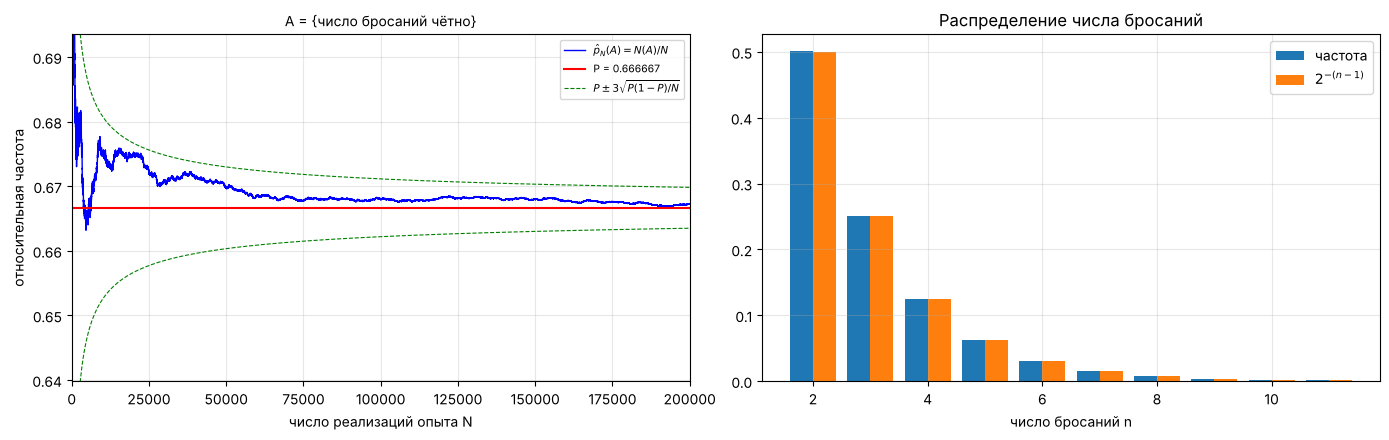

In [3]:
def tosses_until_repeat(p, N, L=80, chunk=50_000):
    # Число бросков до появления двух одинаковых подряд; p — вероятность герба
    out = np.empty(N, dtype=np.int16)
    for s in range(0, N, chunk):
        m = min(chunk, N - s)
        T = rng.random((m, L)) < p                               # True = герб
        same = T[:, 1:] == T[:, :-1]                             # same[:, i] — (i+2)-й бросок совпал с (i+1)-м
        assert same.any(axis=1).all()                            # серия оборвалась в пределах L бросков
        out[s:s + m] = same.argmax(axis=1) + 2                   # номер броска, на котором произошла остановка
    return out

N = 200_000
n_tosses = tosses_until_repeat(0.5, N)
hit_even = n_tosses % 2 == 0
table(hit_even, 2/3, Ns=(100, 1000, 10_000, 100_000, 200_000))
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
plot_frequency(axs[0], hit_even, 2/3, 'A = {число бросаний чётно}')
k = np.arange(2, 12); axs[1].bar(k - 0.2, [np.mean(n_tosses == i) for i in k], 0.4, label='частота'); axs[1].bar(k + 0.2, 2.0**(-(k - 1)), 0.4, label='$2^{-(n-1)}$')
axs[1].set_xlabel('число бросаний n'); axs[1].legend(); axs[1].grid(alpha=0.3); axs[1].set_title('Распределение числа бросаний')
plt.tight_layout(); plt.savefig('task_4_4.png', dpi=130, bbox_inches='tight'); plt.show()

### Ответ:
Модель: $\Omega=\{HH,TT,HTT,THH,HTHH,THTT,\dots\}$, $\mathbb P(N=n)=2^{-(n-1)}$ ($n\ge2$). Вероятность чётного числа бросаний равна $\dfrac23$.